$$
\huge \text{Exploratory Data Analysis (EDA)}
$$

In this notebook, we analyze the structural properties of the MovieLens dataset. Understanding the distribution of target variables (ratings) and categorical features (genres) is essential for selecting appropriate recommendation strategies and handling potential data imbalances.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Configure system path to access source scripts
sys.path.append(os.path.abspath(".."))
PROJECT_ROOT = Path().resolve().parent

from src.features import plot_genre_distribution, plot_value_counts

## 1. Data Loading
We load the processed components of the dataset to verify shapes and initial records.

In [2]:
DATA_DIR = Path("../data/processed")

movies = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")

print(f"Movies Shape: {movies.shape} (Features: {', '.join(movies.columns)})")
print(f"Ratings Shape: {ratings.shape} (Features: {', '.join(ratings.columns)})")

Movies Shape: (87445, 3) (Features: movieId, title, genres)
Ratings Shape: (31957234, 4) (Features: userId, movieId, rating, timestamp)


## 2. Feature Distribution Analysis

### 2.1 Movie Genres Distribution
We visualize the total count of films belonging to each specific cinematic genre. Since a single movie can belong to multiple genres, this represents an overlapping multi-label distribution.

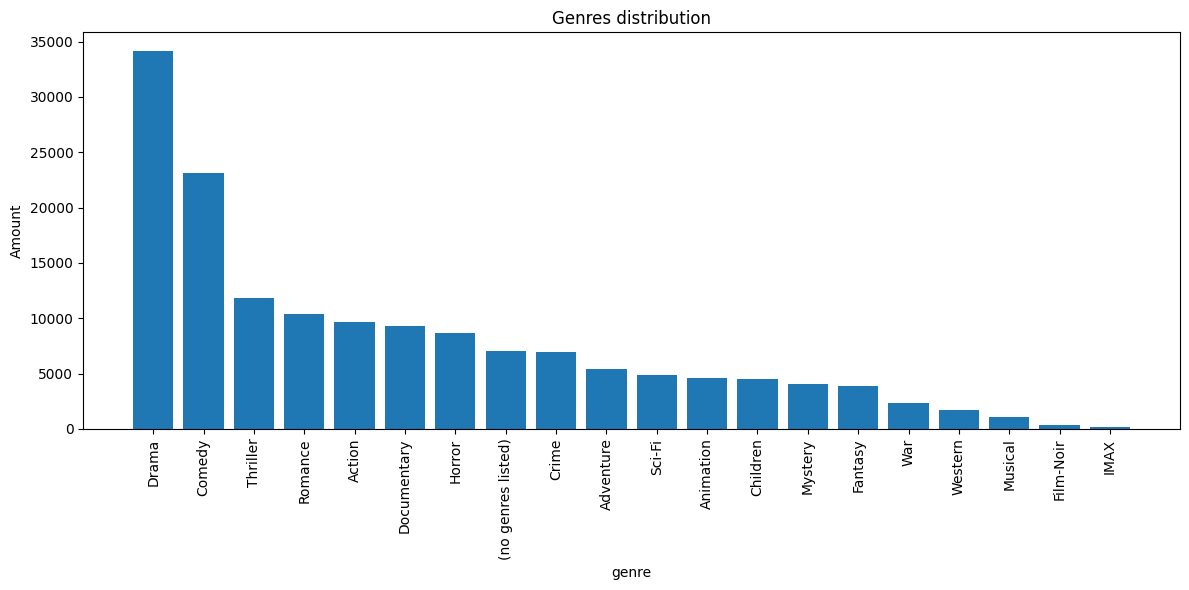


Genre counts:

Drama: 34127
Comedy: 23088
Thriller: 11814
Romance: 10356
Action: 9656
Documentary: 9312
Horror: 8648
(no genres listed): 7079
Crime: 6967
Adventure: 5396
Sci-Fi: 4901
Animation: 4609
Children: 4518
Mystery: 4008
Fantasy: 3849
War: 2319
Western: 1696
Musical: 1053
Film-Noir: 352
IMAX: 195


In [3]:
plot_genre_distribution(movies, "genres", "Genres distribution")

#### Key Insights from Genres Distribution:
* *Drama* and *Comedy* heavily dominate the catalog, accounting for more than 50 000 titles combined.
* ** Genres like *Film-Noir*, *Musical*, and *IMAX* are extremely rare.
* There are 7 079 movies marked as `(no genres listed)`. This highlights the vital importance of incorporating **user tags** (the `tags.csv` dataset) to recover semantic profiles for these otherwise unclassified items.

### 2.2 User Ratings Distribution
We analyze how users score films on the platform. Ratings range from 0.5 to 5.0 with 0.5 increments.

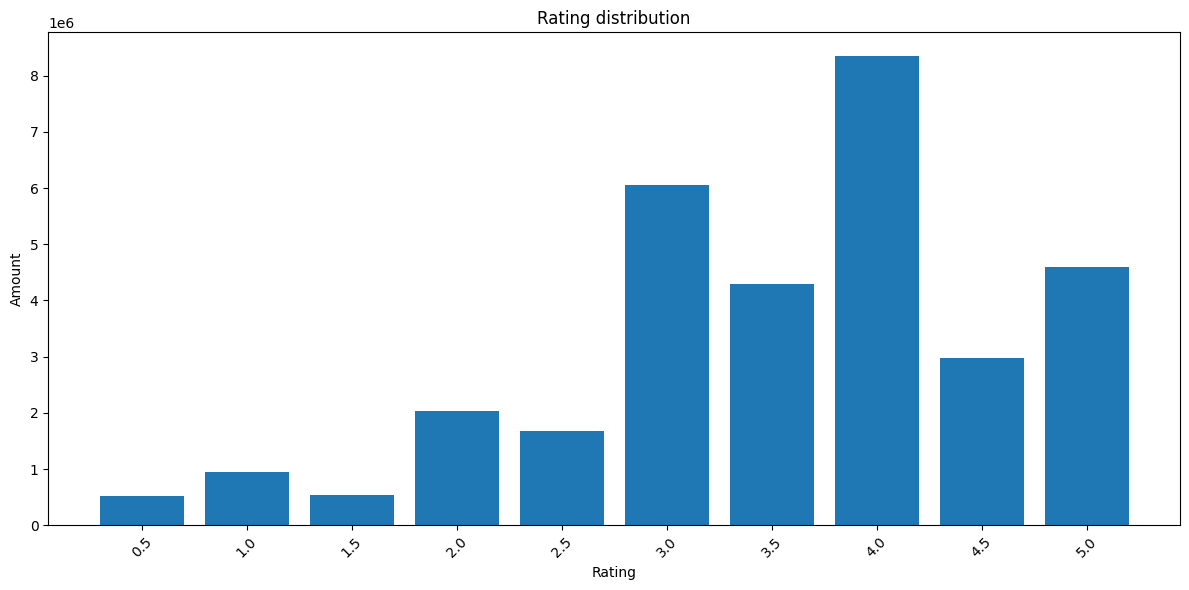


Value counts for 'rating':

0.5: 524762
1.0: 945926
1.5: 530754
2.0: 2026933
2.5: 1684045
3.0: 6047771
3.5: 4284088
4.0: 8353296
4.5: 2969223
5.0: 4590436


In [4]:
plot_value_counts(ratings, "rating", "Rating distribution", "Rating")

#### Key Insights from Ratings Distribution:
* The distribution is heavily left-skewed (skewed toward higher values). The most frequent score given by users is a **4.0** (over 8.3 million instances), followed closely by 3.0 and 5.0.
* Extremely low ratings (0.5 and 1.0) are very rare. 
* Because the data is biased toward positive reviews, standard loss functions like Root Mean Squared Error (RMSE) can be highly sensitive to the few low scores.

### 2.3 Interaction Sparsity Analysis
To understand the complexity of the Collaborative Filtering task, we examine how many ratings are submitted per individual user.

In [5]:
user_activity = ratings.groupby("userId")["rating"].count()

print("User Engagement Statistics:")
print(f" - Minimum ratings given by a single user: {user_activity.min()}")
print(f" - Average (Mean) ratings per user: {user_activity.mean():.1f}")
print(f" - Median ratings per user: {user_activity.median():.1f}")
print(f" - Maximum ratings given by a single user: {user_activity.max()}")

User Engagement Statistics:
 - Minimum ratings given by a single user: 19
 - Average (Mean) ratings per user: 159.0
 - Median ratings per user: 72.0
 - Maximum ratings given by a single user: 33314


In [6]:
num_users = ratings["userId"].nunique()
num_movies = movies["movieId"].nunique()
total_possible_interactions = num_users * num_movies
actual_interactions = len(ratings)

sparsity = (1 - (actual_interactions / total_possible_interactions)) * 100
print(f"Exact Matrix Sparsity: {sparsity:.4f}%")

Exact Matrix Sparsity: 99.8181%


#### Key Insights on Matrix Sparsity & User Behavior:

* There is a large difference between the median user activity (**72 ratings**) and the most active user (**33314 ratings**). This suggests a typical long-tail distribution, where a relatively small group of highly active users generates a large share of all interactions.

* Although some users contribute thousands of ratings, the average user rated only **159 movies** out of a catalog containing more than **30 000 titles**. As a result, the user–item interaction matrix is highly sparse (above **99% sparsity**), which makes recommendation tasks challenging and motivates the use of **Matrix Factorization methods (SGD/SVD)**.

* Another important observation is that even the least active users in the dataset still have at least **19 ratings**. This provides enough interaction history to create meaningful user profiles and supports collaborative filtering approaches.

* Because recommendation data is user-dependent, train–test splitting was performed at the **user level** rather than using a fully random split. This ensures that each user contributes interactions to both training and evaluation and avoids situations where users appear only in the test set.


### 2.4 Distribution of Ratings per Movie

To better understand item popularity, we analyze how many ratings each movie receives.

Movies with very few interactions may be difficult for collaborative filtering methods because there is limited information available to learn user preferences.

In [7]:
movie_activity = ratings.groupby("movieId")["rating"].count()

print("Movie Popularity Statistics:")
print(f" - Minimum ratings received by a single movie: {movie_activity.min()}")
print(f" - Average (Mean) ratings received per movie: {movie_activity.mean():.1f}")
print(f" - Median ratings received per movie:         {movie_activity.median():.1f}")
print(f" - Maximum ratings received by a single movie: {movie_activity.max()}")

# Calculate percentage of movies with very few ratings
low_rated_movies_pct = (movie_activity <= 5).mean() * 100
print(f" - Percentage of movies with 5 or fewer ratings: {low_rated_movies_pct:.1f}%")

Movie Popularity Statistics:
 - Minimum ratings received by a single movie: 1
 - Average (Mean) ratings received per movie: 379.1
 - Median ratings received per movie:         5.0
 - Maximum ratings received by a single movie: 102929
 - Percentage of movies with 5 or fewer ratings: 52.1%


#### Key Insights from Movie Popularity:

* Movie interactions are extremely uneven across the catalog.
* While the average movie receives around **379 ratings**, the median is only **5 ratings**, showing that a small number of highly popular movies strongly influence the average.
* More than **52% of movies received five or fewer ratings**, meaning that most content has very limited interaction history.
* The most popular movie accumulated over **100 thousand ratings**, demonstrating a strong popularity concentration.

#### Impact on Recommendation Modeling:

This observation confirms a classic **long-tail distribution**, which is common in recommendation systems.

Such imbalance creates challenges for collaborative filtering because movies with few interactions provide little information for learning user preferences.

This also motivates the inclusion of:

* **Content-Based Filtering**, which uses movie attributes instead of interaction counts,
* **Hybrid recommendations**, which combine behavioral and content information to improve coverage of less popular items.
